# 08 – Radius sensitivity (200 / 300 / 500 m)

In 07 we replaced the in-cell POI and intersection counts with counts **per ha within 300 m**. The 300 m was a choice (about a 4-minute walk).
Here we check whether the result depends on that choice: we repeat exactly the same pipeline with **200 m** and **500 m** and compare.

What we want to know:
1. **Speckle:** does neighbour agreement keep rising with the radius? (It should – a bigger window is smoother – so more is not automatically better.)
2. **Agreement:** how similar are the clusterings at 200 / 300 / 500 m (ARI)? If they are very similar, 300 m is a safe choice.
3. **Choice of k:** is k = 5 the most seed-stable for every radius, or only for 300 m?
4. **Meaning:** does the low-density vs dense residential split at k = 6 appear for every radius?

The in-cell version from 06 is included as a reference ("in cell").

- **Input:** `cells.gpkg`, `ind_*.csv`
- **Output:** `data/processed/radius_sensitivity.csv`, figures `08_*.png`

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.ndimage import convolve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

SEED = 0
K_RANGE = range(4, 13)
RADII = [0, 200, 300, 500]   # m; 0 = counts inside the cell (as in 06)
CELL = 100                   # m
WATER_THRESHOLD = 0.5
DORM_CELL = "SIHM100_4603_1014"
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

## 2. Load

In [2]:
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")
data = cells.set_index("cell_id").drop(columns="geometry")
for name in ["buildings", "land_cover", "poi", "streets"]:
    data = data.join(pd.read_csv(PROCESSED / f"ind_{name}.csv", index_col="cell_id"))

col_idx = ((data["E"] - data["E"].min()) // CELL).astype(int).values
row_idx = ((data["N"] - data["N"].min()) // CELL).astype(int).values
shape = (row_idx.max() + 1, col_idx.max() + 1)
present = np.zeros(shape)
present[row_idx, col_idx] = 1

use = data["bld_in_data"] & ~(data["ndvi_neg_share"] > WATER_THRESHOLD)
print(f"Clustered cells: {use.sum():,}")

C:\Users\Maks\miniforge3\envs\urban\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Clustered cells: 16,351


## 3. Radius counts for each radius
Same disc-shaped window as in 07, only the radius changes. Window sizes: 200 m → 13 cells, 300 m → 29 cells, 500 m → 81 cells.
For radius 0 we keep the plain in-cell counts.

In [3]:
def disc(radius):
    r = radius // CELL
    dy, dx = np.mgrid[-r:r + 1, -r:r + 1]
    return ((dx ** 2 + dy ** 2) * CELL ** 2 <= radius ** 2).astype(float)

def radius_density(values, radius):
    if radius == 0:
        return values
    w = disc(radius)
    grid = np.zeros(shape)
    grid[row_idx, col_idx] = values
    with np.errstate(invalid="ignore"):
        return (convolve(grid, w, mode="constant") / convolve(present, w, mode="constant"))[row_idx, col_idx]

FEATURES = ["pop", "imp_share", "bld_height", "can_cover", "poi", "str_intersections"]
LOG_FEATURES = ["pop", "poi", "str_intersections"]

def build_Z(radius):
    X = data[["pop", "imp_share", "bld_height", "can_cover"]].copy()
    X["poi"] = radius_density(data["poi_count"].values, radius)
    X["str_intersections"] = radius_density(data["str_intersections"].values, radius)
    X = X.loc[use, FEATURES]
    X.loc[DORM_CELL, "pop"] = X["pop"].drop(DORM_CELL).max()
    X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])
    return X, pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=FEATURES)

for radius in RADII[1:]:
    print(f"{radius} m: {int(disc(radius).sum())} cells in window")
Zs = {radius: build_Z(radius)[1] for radius in RADII}

200 m: 13 cells in window
300 m: 29 cells in window
500 m: 81 cells in window


## 4. Cluster for every radius and every k
Same as 06/07: k-means with 20 starts for the labels, plus 10 single-start runs with different seeds for **seed stability** (mean and minimum pairwise ARI).
Labels are reordered by mean imperviousness so that cluster numbers are comparable between radii.

In [4]:
def neighbour_agreement(lab):
    grid = np.full(shape, -1)
    pos = data.index.get_indexer(lab.index)
    rr, cc = row_idx[pos], col_idx[pos]
    grid[rr, cc] = lab.values
    same = np.zeros(len(lab))
    total = np.zeros(len(lab))
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == dj == 0:
                continue
            ni, nj = rr + di, cc + dj
            ok = (ni >= 0) & (ni < shape[0]) & (nj >= 0) & (nj < shape[1])
            neigh = np.full(len(lab), -1)
            neigh[ok] = grid[ni[ok], nj[ok]]
            valid = neigh >= 0
            same += valid & (neigh == lab.values)
            total += valid
    return np.mean(same[total > 0] / total[total > 0])

rows, labels = [], {}
for radius in RADII:
    Z = Zs[radius]
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
        order = Z.groupby(km.labels_)["imp_share"].mean().sort_values().index
        lab = pd.Series(km.labels_, index=Z.index).map({old: new for new, old in enumerate(order)})
        labels[radius, k] = lab
        runs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(Z) for s in range(10)]
        aris = [adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)]
        rows.append({
            "radius": radius, "k": k,
            "silhouette": silhouette_score(Z, km.labels_, sample_size=10_000, random_state=SEED),
            "davies_bouldin": davies_bouldin_score(Z, km.labels_),
            "seed_ari_mean": np.mean(aris),
            "seed_ari_min": np.min(aris),
            "neighbour_agreement": neighbour_agreement(lab),
            "smallest_cluster": lab.value_counts().min(),
        })
scores = pd.DataFrame(rows).set_index(["radius", "k"])
scores.round(3)

silhouette  davies_bouldin  seed_ari_mean  seed_ari_min  \
radius k                                                             
0      4        0.444           1.104          0.680         0.416   
       5        0.471           0.984          0.767         0.411   
       6        0.491           0.947          0.945         0.802   
       7        0.496           1.046          0.890         0.798   
       8        0.502           1.103          0.887         0.781   
       9        0.507           1.061          0.867         0.764   
       10       0.480           1.076          0.884         0.775   
       11       0.487           1.054          0.888         0.781   
       12       0.492           1.057          0.875         0.635   
200    4        0.425           1.070          0.752         0.379   
       5        0.445           1.074          0.999         0.998   
       6        0.429           1.130          0.917         0.845   
       7        0.422           1.184          0.866         0.761   
       8        0.412           1.188          0.979         0.940   
       9        0.419           1.176          0.863         0.719   
       10       0.420           1.165          0.801         0.666   
       11       0.413           1.204          0.806         0.681   
       12       0.381           1.180          0.818         0.706   
300    4        0.415           1.072          0.888         0.448   
       5        0.434           1.071          0.997         0.993   
       6        0.420           1.071          0.862         0.752   
       7        0.396           1.183          0.788         0.589   
       8        0.399           1.186          0.862         0.650   
       9        0.403           1.150          0.881         0.655   
       10       0.403           1.137          0.847         0.686   
       11       0.399           1.211          0.805         0.669   
       12       0.363           1.158          0.800         0.652   
500    4        0.396           1.119          0.877         0.438   
       5        0.416           1.076          0.890         0.772   
       6        0.412           1.021          0.894         0.632   
       7        0.382           1.136          0.812         0.631   
       8        0.385           1.119          0.904         0.830   
       9        0.384           1.114          0.904         0.846   
       10       0.377           1.134          0.870         0.684   
       11       0.340           1.131          0.827         0.692   
       12       0.335           1.179          0.784         0.671   

           neighbour_agreement  smallest_cluster  
radius k                                          
0      4                 0.703              1379  
       5                 0.632              1270  
       6                 0.632               710  
       7                 0.609               398  
       8                 0.591               394  
       9                 0.587               171  
       10                0.543               164  
       11                0.534               154  
       12                0.534               143  
200    4                 0.768              1018  
       5                 0.739               761  
       6                 0.682               617  
       7                 0.664               216  
       8                 0.647               208  
       9                 0.645               149  
       10                0.640               153  
       11                0.613               145  
       12                0.562               139  
300    4                 0.776              1030  
       5                 0.745               755  
       6                 0.714               458  
       7                 0.670               361  
       8                 0.660               257  
       9                 0.658               153  
       10               

### Seed stability and speckle by k
Left: which k is most seed-stable for each radius. Right: neighbour agreement (higher = less speckle).

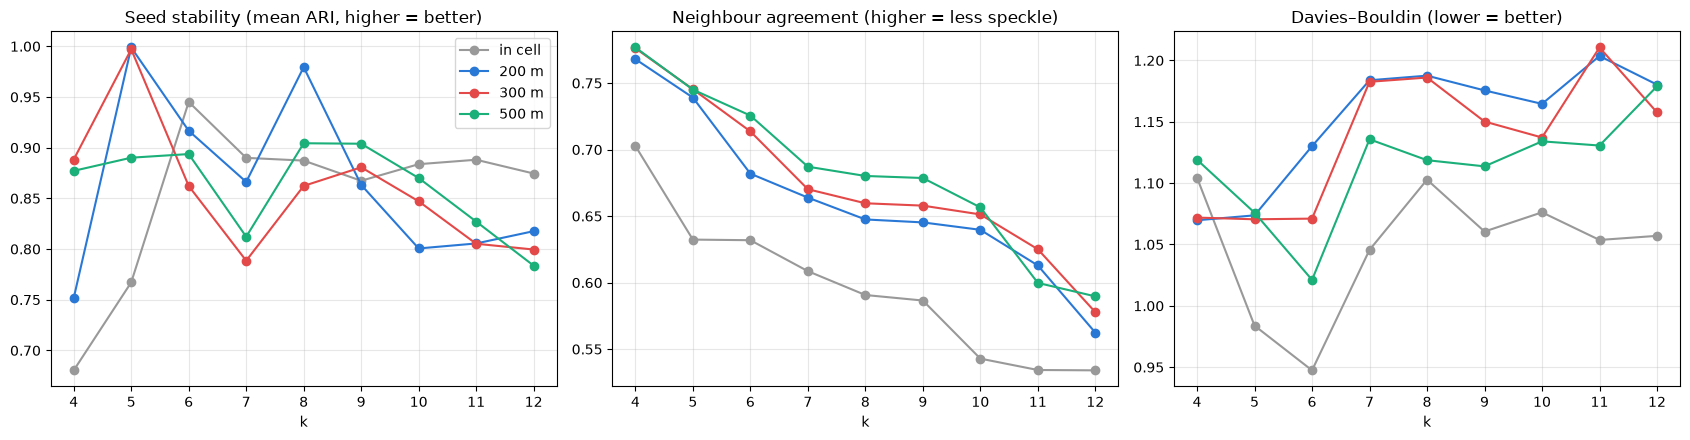

Most seed-stable k per radius:
radius
0      6
200    5
300    5
500    8


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for radius, color in zip(RADII, ["#999999", "#2a78d6", "#e34948", "#1baf7a"]):
    s = scores.loc[radius]
    name = "in cell" if radius == 0 else f"{radius} m"
    axes[0].plot(s.index, s["seed_ari_mean"], "o-", color=color, label=name)
    axes[1].plot(s.index, s["neighbour_agreement"], "o-", color=color, label=name)
    axes[2].plot(s.index, s["davies_bouldin"], "o-", color=color, label=name)
axes[0].set_title("Seed stability (mean ARI, higher = better)")
axes[1].set_title("Neighbour agreement (higher = less speckle)")
axes[2].set_title("Davies–Bouldin (lower = better)")
for ax in axes:
    ax.set_xlabel("k")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
fig.savefig(FIGURES / "08_scores_by_radius.png", dpi=150, bbox_inches="tight")
plt.show()

print("Most seed-stable k per radius:")
print(scores["seed_ari_mean"].groupby("radius").idxmax().map(lambda t: t[1]).to_string())

## 5. How similar are the radii? (ARI between clusterings)
For k = 5 and k = 6: ARI between every pair of radii. Values close to 1 mean the radius choice hardly matters.

In [6]:
names = {r: ("in cell" if r == 0 else f"{r} m") for r in RADII}
for k in (5, 6):
    m = pd.DataFrame(
        [[adjusted_rand_score(labels[a, k], labels[b, k]) for b in RADII] for a in RADII],
        index=[names[r] for r in RADII], columns=[names[r] for r in RADII],
    ).round(3)
    print(f"k = {k}")
    display(m)

k = 5


,in cell,200 m,300 m,500 m
in cell,1.000,0.768,0.751,0.746
200 m,0.768,1.000,0.929,0.884
300 m,0.751,0.929,1.000,0.920
500 m,0.746,0.884,0.920,1.000


k = 6


,in cell,200 m,300 m,500 m
in cell,1.000,0.754,0.807,0.793
200 m,0.754,1.000,0.809,0.770
300 m,0.807,0.809,1.000,0.907
500 m,0.793,0.770,0.907,1.000


## 6. Does the residential split survive? (k = 6)
For each radius, the medians of the original variables per cluster. We look for two residential clusters that differ in density
(population, height, POI nearby) – the split we found at 300 m.

In [7]:
profiles = []
for radius in RADII:
    X = build_Z(radius)[0]
    raw = data.loc[X.index, ["pop", "bld_height", "imp_share", "can_cover"]].assign(
        poi=np.expm1(X["poi"]), str_intersections=np.expm1(X["str_intersections"]))
    g = raw.groupby(labels[radius, 6])
    p = g.median().round(2)
    p.insert(0, "cells", g.size())
    p.insert(1, "residents", g["pop"].sum().astype(int))
    p.insert(0, "radius", names[radius])
    profiles.append(p)
profiles = pd.concat(profiles).rename_axis("cluster").reset_index().set_index(["radius", "cluster"])
profiles

cells  residents   pop  bld_height  imp_share  can_cover  \
radius  cluster                                                             
in cell 0         4189        449   0.0        0.00       0.00       0.94   
        1         6085       1450   0.0        0.00       0.00       0.06   
        2         2232     139673  35.0        8.06       0.40       0.09   
        3         1889      92447  35.0        8.21       0.50       0.07   
        4         1246        388   0.0        9.76       0.74       0.04   
        5          710      56553  36.0       14.13       0.71       0.09   
200 m   0         4132        265   0.0        0.00       0.00       0.95   
        1         5398        115   0.0        0.00       0.00       0.06   
        2         2357      25583   7.0        7.29       0.21       0.09   
        3         2574     196599  53.0        8.58       0.53       0.08   
        4          617      67836  68.0       17.81       0.73       0.11   
        5         1273        562   0.0        9.80       0.76       0.03   
300 m   0         4185        360   0.0        0.00       0.00       0.94   
        1         5952        575   0.0        0.00       0.00       0.06   
        2         2287      63535  20.0        7.57       0.31       0.07   
        3         1957     182283  65.0        9.46       0.56       0.09   
        4         1512        483   0.0        9.45       0.70       0.04   
        5          458      43724  42.0       18.67       0.79       0.09   
500 m   0         4207        352   0.0        0.00       0.00       0.94   
        1         6039        751   0.0        0.00       0.00       0.06   
        2         2501      75236  23.0        7.64       0.34       0.07   
        3         1793     189442  72.0       10.27       0.57       0.11   
        4         1541        448   0.0        9.77       0.73       0.04   
        5          270      24731  52.5       20.59       0.76       0.12   

                  poi  str_intersections  
radius  cluster                           
in cell 0        0.00               0.00  
        1        0.00               0.00  
        2        0.00               0.00  
        3        0.00               1.00  
        4        0.00               0.00  
        5        2.00               1.00  
200 m   0        0.00               0.00  
        1        0.00               0.00  
        2        0.00               0.30  
        3        0.23               0.69  
        4        1.62               0.92  
        5        0.23               0.23  
300 m   0        0.00               0.00  
        1        0.00               0.07  
        2        0.07               0.31  
        3        0.41               0.69  
        4        0.24               0.38  
        5        1.76               0.97  
500 m   0        0.00               0.01  
        1        0.01               0.12  
        2        0.10               0.31  
        3        0.48               0.64  
        4        0.32               0.44  
        5        2.48               1.07

**Cross-tables against 300 m** (k = 6): where do the 300 m clusters end up at 200 m and 500 m? Rows = 300 m clusters, values = share of the row.

In [8]:
for radius in (200, 500):
    print(f"300 m (rows) vs {radius} m (columns), k = 6")
    display(pd.crosstab(labels[300, 6].rename("300 m"), labels[radius, 6].rename(f"{radius} m"), normalize="index").round(2))

300 m (rows) vs 200 m (columns), k = 6


200 m,0,1,2,3,4,5
300 m,,,,,,
0,0.98,0.01,0.01,0.00,0.00,0.00
1,0.00,0.90,0.10,0.00,0.00,0.00
2,0.00,0.00,0.65,0.35,0.00,0.00
3,0.00,0.00,0.01,0.89,0.09,0.00
4,0.00,0.01,0.15,0.01,0.01,0.81
5,0.00,0.00,0.00,0.03,0.91,0.05


300 m (rows) vs 500 m (columns), k = 6


500 m,0,1,2,3,4,5
300 m,,,,,,
0,0.99,0.01,0.00,0.00,0.00,0.00
1,0.01,0.98,0.00,0.00,0.01,0.00
2,0.00,0.03,0.93,0.03,0.00,0.00
3,0.00,0.00,0.17,0.81,0.01,0.01
4,0.00,0.07,0.01,0.00,0.91,0.01
5,0.00,0.00,0.00,0.24,0.21,0.54


## 7. Maps (k = 6)

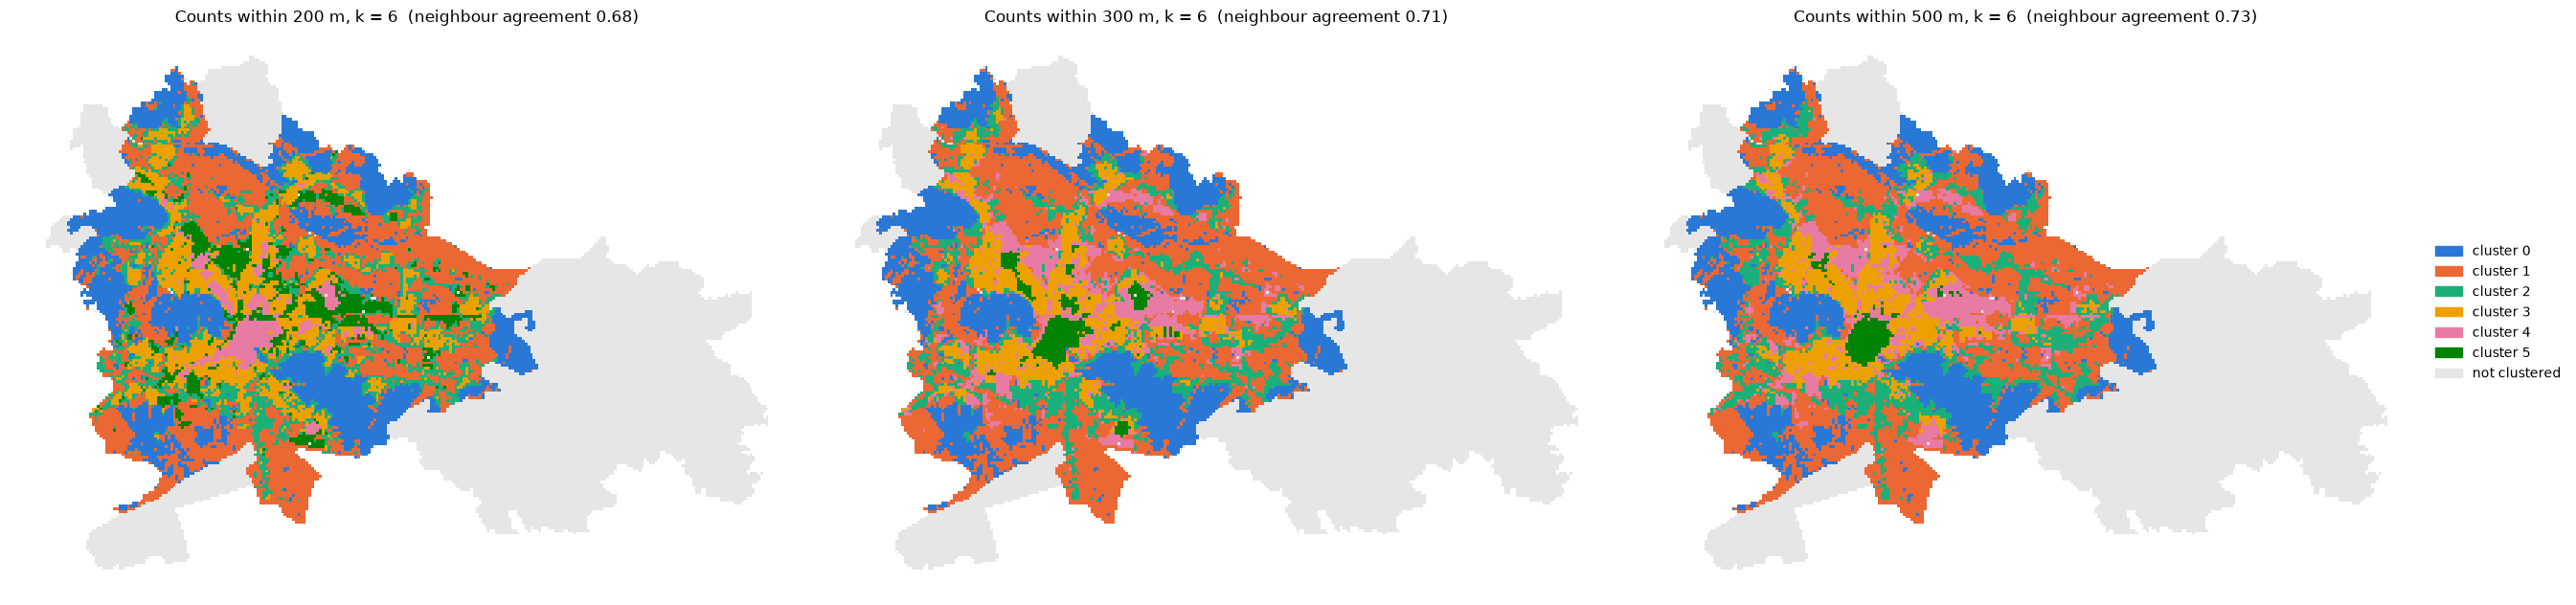

In [9]:
K = 6
cmap = ListedColormap(CLUSTER_COLORS[:K])
fig, axes = plt.subplots(1, 3, figsize=(27, 9))
for ax, radius in zip(axes, [200, 300, 500]):
    g_ = cells[["cell_id", "geometry"]].merge(labels[radius, K].rename("cluster").reset_index(), on="cell_id", how="left")
    g_[g_["cluster"].isna()].plot(ax=ax, color="#e6e6e6", linewidth=0)
    g_.dropna(subset=["cluster"]).plot(ax=ax, column="cluster", cmap=cmap, vmin=-0.5, vmax=K - 0.5, linewidth=0)
    ax.set_title(f"Counts within {radius} m, k = {K}  (neighbour agreement {scores.loc[(radius, K), 'neighbour_agreement']:.2f})")
    ax.set_axis_off()
handles = [Patch(color=CLUSTER_COLORS[c], label=f"cluster {c}") for c in range(K)] + [Patch(color="#e6e6e6", label="not clustered")]
axes[2].legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
fig.savefig(FIGURES / "08_maps_by_radius.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Save

In [10]:
scores.reset_index().to_csv(PROCESSED / "radius_sensitivity.csv", index=False)
print("Saved radius_sensitivity.csv")

Saved radius_sensitivity.csv


## Summary (first run, 1 Nov 2026)

**Speckle:** any radius removes most of it (neighbour agreement at k = 6: in cell 0.63, 200 m 0.68, 300 m 0.71, 500 m 0.73). Beyond 300 m the gain is small, and at k = 5 there is none (0.75 for both).

**Agreement between radii:**
- k = 5: the radius hardly matters (ARI 0.88–0.93 between 200, 300 and 500 m).
- k = 6: 300 m and 500 m agree (ARI 0.91); 200 m differs (ARI 0.81 vs 300 m).

**Meaning at k = 6:**
- 300 m and 500 m both give the split **low-density residential** (20–23 residents/ha) vs **dense urban residential** (65–72 residents/ha). The centre cluster gets smaller as the radius grows (458 → 270 cells): a larger window smooths secondary centres away.
- At 200 m the split is different: a small sparse fringe cluster (7 residents/ha) vs one big residential cluster with almost all residents, and a larger centre (617 cells). 200 m is too small a neighbourhood to separate the two residential types.
- Note: at 200 m the centre is cluster 4 and non-residential is cluster 5 (clusters are numbered by mean imperviousness), so the colours swap on the map.

**Choice of k:** k = 5 is the most seed-stable for 200 m and 300 m (ARI 0.999 / 0.997) but not for 500 m (0.89; k = 8 best there).

**Proposed:** keep **300 m**. It agrees with 500 m, gives a very stable k = 5, and keeps the centre compact without smoothing it away. Still open: k = 5 (stable) vs k = 6 (residential split, seed ARI 0.86).